In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [39]:
from pathlib import Path
import numpy as np
import os
import cv2
import random
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from tensorflow.keras import layers,models

IMG_SIZE = (224, 224)
DRIVE_DIR = Path('/content/drive/MyDrive/NeuralVisionAI/data/raw')
DRIVE_DIR.is_dir()

True

In [3]:
dir_names = {}
n_images = 0
for dir in DRIVE_DIR.iterdir():
  if dir.is_dir():
    n_images_per_class = len(list(dir.iterdir()))
    print(f'{dir.name}: {n_images_per_class}')
    dir_names[dir.name]=n_images_per_class
    n_images += n_images_per_class
print(f'Total images: {n_images}')

notumor: 2000
pituitary: 1757
meningioma: 1645
glioma: 1621
Total images: 7023


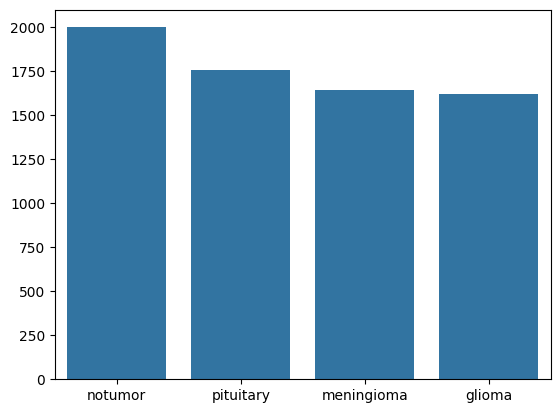

In [4]:
sns.barplot(x=list(dir_names.keys()), y=list(dir_names.values()))
plt.show()

In [5]:
for class_name in dir_names:
  images_path = (DRIVE_DIR/class_name)
  if images_path.is_dir():
    for image in images_path.iterdir():
      if not image.is_file():
        os.remove(image)
      if image.suffix.lower() not in {'.jpg','.png','.jpe','.bmp','.png'}:
        os.remove(image)

In [6]:
for class_name in dir_names:
  images_path = (DRIVE_DIR/class_name)
  if images_path.is_dir():
    for image in images_path.iterdir():
      try:
        img = cv2.imread(str(image))
        if img is None:
          print("Unreadable or corrupted image: ",image)
          os.remove(image)
      except cv2.error as error:
        print('Reading error: ',image,error)


In [7]:
images = []
labels = []
for class_name in dir_names:
  images_path = (DRIVE_DIR/class_name)
  if images_path.is_dir():
    for image in images_path.iterdir():
      img = cv2.imread(str(image))
      images.append(img)
      labels.append(class_name)


In [8]:
print("Nombre d'images :", len(images))
print("Nombre de labels :", len(labels))

assert len(images) == len(labels)

Nombre d'images : 7023
Nombre de labels : 7023


In [9]:
images_resized = [
    cv2.resize(image, IMG_SIZE)
    for image in images
]

images = np.array(images_resized)

print("Forme des images :", images.shape)

Forme des images : (7023, 224, 224, 3)


In [10]:
combined = list(zip(images, labels))
random.seed(42)
random.shuffle(combined)

images, lables = zip(*combined)

images = list(images)
images = np.array(images)
lables = list(lables)
labels = np.array(lables,dtype="object")

In [11]:
print("Forme des images :", images.shape)
print("Forme des labels :", labels.shape)
print("Type des images :", images.dtype)
print("Type des labels :", labels.dtype)
print("Exemples de labels :", labels[:10])

assert len(images) == len(labels)

Forme des images : (7023, 224, 224, 3)
Forme des labels : (7023,)
Type des images : uint8
Type des labels : object
Exemples de labels : ['glioma' 'pituitary' 'pituitary' 'notumor' 'notumor' 'meningioma'
 'meningioma' 'glioma' 'meningioma' 'pituitary']


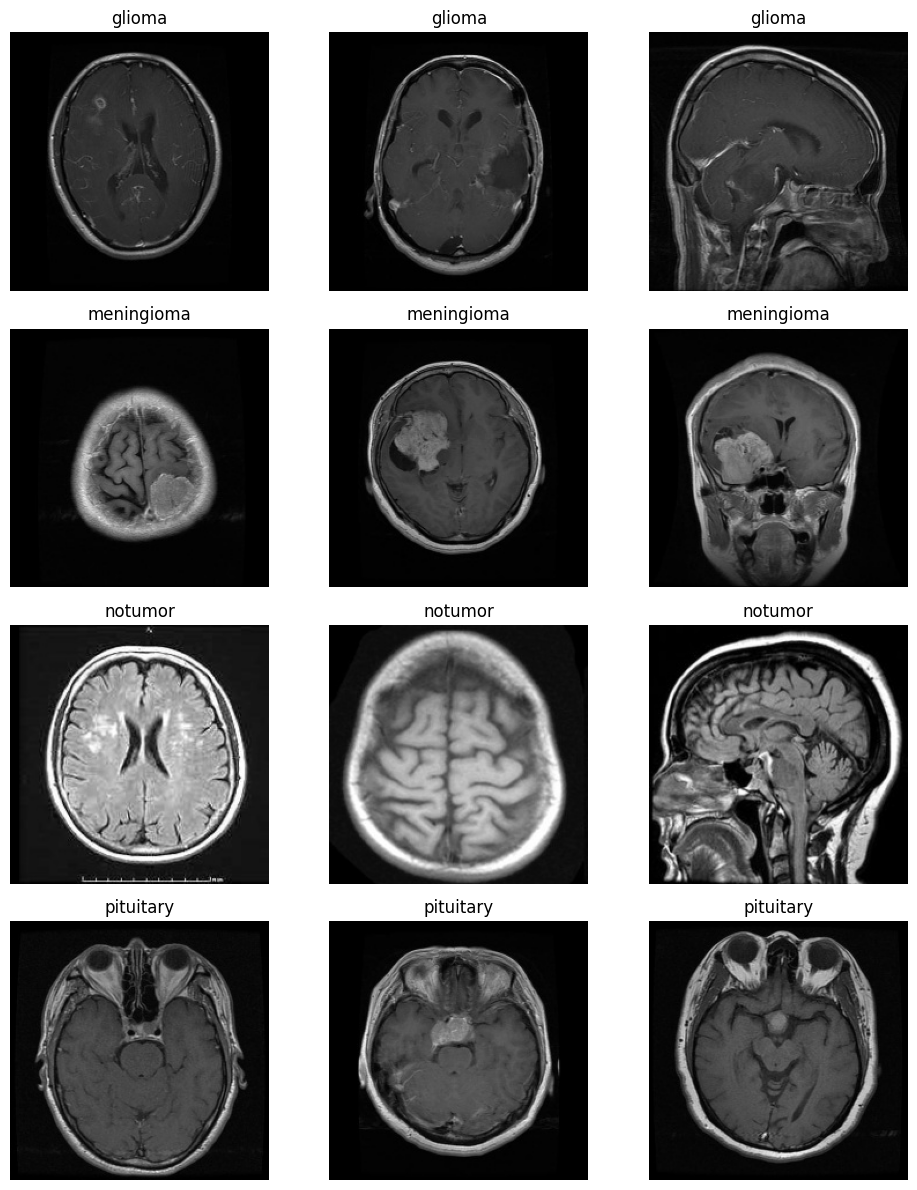

In [12]:
class_names = np.unique(labels)
n_images = 3

fig, axes = plt.subplots(
    len(class_names),
    n_images,
    figsize=(10, 3 * len(class_names))
)

for row, class_name in enumerate(class_names):
    class_indices = np.where(labels == class_name)[0]
    selected_indices = random.sample(
        list(class_indices),
        min(n_images, len(class_indices))
    )

    for col, index in enumerate(selected_indices):
        image = images[index]

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        axes[row, col].imshow(image_rgb)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [13]:
from pathlib import Path
import tensorflow as tf

def load_dataset(
    data_dir,
    img_size=(224, 224),
    batch_size=32,
    training=False,
    cache_path=None
):
    data_dir = Path(data_dir)
    extensions = {".jpg", ".jpeg", ".png", ".bmp"}

    class_names = sorted(
        folder.name for folder in data_dir.iterdir()
        if folder.is_dir()
    )

    paths = []
    labels = []

    for label, class_name in enumerate(class_names):
        class_dir = data_dir / class_name

        for file in sorted(class_dir.iterdir()):
            if file.is_file() and file.suffix.lower() in extensions:
                paths.append(str(file))
                labels.append(label)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    def preprocess(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )
        image.set_shape([None, None, 3])

        image = tf.image.resize(image, img_size)
        image = tf.cast(image, tf.float32) / 255.0

        return image, label

    dataset = dataset.map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if cache_path is not None:
        dataset = dataset.cache(str(cache_path))

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset, class_names

In [14]:
class_counts = pd.Series(labels).value_counts().sort_index()
max_count = class_counts.max()
min_count = class_counts.min()

print("Classe majoritaire :", class_counts.idxmax(), max_count)
print("Classe minoritaire :", class_counts.idxmin(), min_count)
print("Rapport de déséquilibre :", round(max_count / min_count, 2))

Classe majoritaire : notumor 2000
Classe minoritaire : glioma 1621
Rapport de déséquilibre : 1.23


In [15]:
# from sklearn.utils.class_weight import compute_class_weight

# # Les classes doivent être représentées par des entiers.
# # Ici, labels_num correspond aux labels numériques du dataset.
# classes = np.unique(labels_num)

# weights = compute_class_weight(
#     class_weight="balanced",
#     classes=classes,
#     y=labels_num
# )

# class_weights = dict(zip(classes, weights))

# print(class_weights)

In [16]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

labels_num = label_encoder.fit_transform(labels)

print("Classes :", label_encoder.classes_)
print("Labels numériques :", labels_num[:10])

Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']
Labels numériques : [0 3 3 2 2 1 1 0 1 3]


In [17]:
from tensorflow.keras.utils import to_categorical

labels_onehot = to_categorical(labels_num, num_classes=4)

print("Forme des labels numériques :", labels_num.shape)
print("Forme des labels one-hot :", labels_onehot.shape)
print("Exemple :", labels_onehot[0])

Forme des labels numériques : (7023,)
Forme des labels one-hot : (7023, 4)
Exemple : [1. 0. 0. 0.]


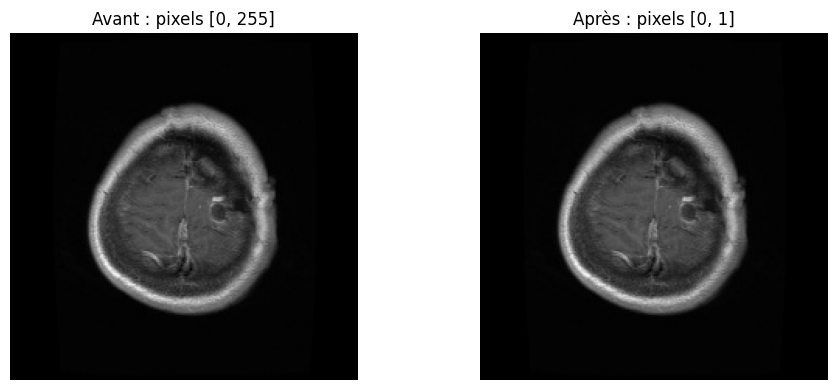

Minimum avant : 0
Maximum avant : 253
Minimum après : 0.0
Maximum après : 0.99215686


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Sélectionner une image
image_before = images[0]

# OpenCV utilise BGR ; convertir en RGB pour Matplotlib
image_before_rgb = cv2.cvtColor(image_before, cv2.COLOR_BGR2RGB)

# Normaliser les pixels
image_after = image_before.astype(np.float32) / 255.0

# Convertir aussi l'image normalisée en RGB pour l'affichage
image_after_rgb = cv2.cvtColor(image_after, cv2.COLOR_BGR2RGB)

# Afficher la comparaison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image_before_rgb)
axes[0].set_title("Avant : pixels [0, 255]")
axes[0].axis("off")

axes[1].imshow(image_after_rgb)
axes[1].set_title("Après : pixels [0, 1]")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Minimum avant :", image_before.min())
print("Maximum avant :", image_before.max())
print("Minimum après :", image_after.min())
print("Maximum après :", image_after.max())

In [19]:
# import tensorflow as tf
# from tensorflow import keras
# from tensorflow.keras import layers

# data_augmentation = keras.Sequential([
#     layers.RandomRotation(0.05),
#     layers.RandomZoom(0.10),
#     layers.RandomTranslation(
#         height_factor=0.05,
#         width_factor=0.05
#     )
# ], name="data_augmentation")

# import matplotlib.pyplot as plt
# import cv2
# import numpy as np

# image = cv2.cvtColor(images[0], cv2.COLOR_BGR2RGB)
# image = image.astype(np.float32) / 255.0

# augmented_images = data_augmentation(
#     tf.expand_dims(image, axis=0),
#     training=True
# )

# fig, axes = plt.subplots(1, 4, figsize=(12, 4))

# axes[0].imshow(image)
# axes[0].set_title("Originale")
# axes[0].axis("off")

# for i in range(1, 4):
#     axes[i].imshow(augmented_images[0].numpy())
#     axes[i].set_title(f"Augmentation {i}")
#     axes[i].axis("off")

# plt.tight_layout()
# plt.show()

# model = keras.Sequential([
#     layers.Input(shape=(224, 224, 3)),

#     data_augmentation,

#     layers.Conv2D(32, 3, activation="relu"),
#     layers.MaxPooling2D(),

#     # Les autres couches du CNN viendront ici.
# ])

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    images,
    labels_num,
    test_size=0.20,
    random_state=42,
    stratify=labels_num
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (5618, 224, 224, 3)
X_test  : (1405, 224, 224, 3)
y_train : (5618,)
y_test  : (1405,)


In [21]:
my_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    # Block 1
    layers.Conv2D(32, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3),activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

my_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir="./training_backup"
    )
]

In [25]:
my_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history = my_model.fit(X_train,y_train,epochs=15,batch_size=32,callbacks=callbacks,validation_split=0.2,verbose=2)

Epoch 1/15
141/141 - 16s - 116ms/step - accuracy: 0.8723 - loss: 0.3450 - val_accuracy: 0.8986 - val_loss: 0.3012
Epoch 2/15
141/141 - 9s - 63ms/step - accuracy: 0.8899 - loss: 0.2892 - val_accuracy: 0.8959 - val_loss: 0.3007
Epoch 3/15
141/141 - 9s - 62ms/step - accuracy: 0.9045 - loss: 0.2620 - val_accuracy: 0.8923 - val_loss: 0.3137
Epoch 4/15
141/141 - 9s - 62ms/step - accuracy: 0.8999 - loss: 0.2757 - val_accuracy: 0.8790 - val_loss: 0.3116
Epoch 5/15
141/141 - 9s - 63ms/step - accuracy: 0.8939 - loss: 0.2807 - val_accuracy: 0.9173 - val_loss: 0.2533
Epoch 6/15
141/141 - 9s - 65ms/step - accuracy: 0.9059 - loss: 0.2595 - val_accuracy: 0.9075 - val_loss: 0.2883
Epoch 7/15
141/141 - 9s - 63ms/step - accuracy: 0.9146 - loss: 0.2278 - val_accuracy: 0.9057 - val_loss: 0.2794
Epoch 8/15
141/141 - 9s - 64ms/step - accuracy: 0.9261 - loss: 0.1921 - val_accuracy: 0.9155 - val_loss: 0.2436
Epoch 9/15
141/141 - 9s - 65ms/step - accuracy: 0.9319 - loss: 0.1760 - val_accuracy: 0.8915 - val_los

In [26]:
test_loss, test_acc = my_model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy = {test_acc:.3f}")

Test accuracy = 0.905


In [27]:
predictions = my_model.predict(X_test)
print("Predicted class:", np.argmax(predictions[0]))
print("Actual class:", np.argmax(y_test[0]))


44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step
Predicted class: 1
Actual class: 0


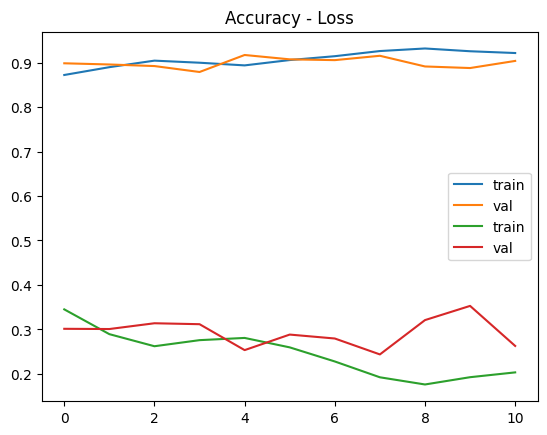

In [33]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title('Accuracy - Loss')
plt.show()

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


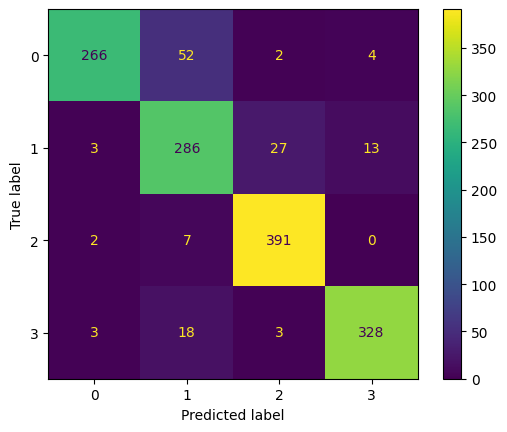

In [40]:
y_pred_proba = my_model.predict(X_test)
y_pred = np.argmax(y_pred_proba,axis=1)
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

In [ ]:

from pathlib import Path
import tensorflow as tf

def predict_image(path):
    path = Path(path)

    if not path.is_file():
        print(f"Error: image not found: {path}")
        return None

    extensions = {".jpg", ".jpeg", ".png", ".bmp"}

    if path.suffix.lower() not in extensions:
        print("Error: unsupported image format.")
        return None

    try:
        image_bytes = tf.io.read_file(str(path))

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(image, (224, 224))

        image = tf.cast(image, tf.float32) / 255.0

        image = tf.expand_dims(image, axis=0)

        predictions = my_model.predict(image, verbose=0)

        predicted_index = int(tf.argmax(
            predictions[0]
        ).numpy())

        confidence = float(predictions[0][predicted_index])

        class_name = class_names[predicted_index]

        return {
            "class": class_name,
            "confidence": confidence
        }

    except (tf.errors.OpError, ValueError, OSError) as error:
        print(f"Error processing image: {error}")
        return None


In [ ]:
# my_model.save("../model/cnn_model.keras")